# ChestScan AI — CNN for chest X-ray classification (NORMAL vs PNEUMONIA)

**Pipeline:** download → explore → imbalance → patient-wise split → tf.data (resize + normalize) → CNN → train → evaluate on test → error analysis.

**Dataset:** Kaggle *Chest X-Ray Images (Pneumonia)* — `paultimothymooney/chest-xray-pneumonia`.

## 1. Imports :

In [30]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
from PIL import Image
from collections import Counter
from tensorflow.keras.preprocessing.image import ImageDataGenerator

## 2. Chargement et prétraitement du dataset :

### 2.1 Charger le dataset de radiographies thoraciques fourni pour le projet

In [3]:
DATA_DIR = Path(
    r"C:\Users\USER\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray"
)

### 2.2 Explorer la structure des dossiers et identifier les classes présentes :

In [9]:
for doc in DATA_DIR.iterdir():
    for d in doc.iterdir():
        print(doc.name,"->",d.name)

chest_xray -> .DS_Store
chest_xray -> test
chest_xray -> train
chest_xray -> val
test -> NORMAL
test -> PNEUMONIA
train -> NORMAL
train -> PNEUMONIA
val -> NORMAL
val -> PNEUMONIA
__MACOSX -> ._chest_xray
__MACOSX -> chest_xray


### 2.3 Vérifier le nombre d'images disponibles dans chaque classe:

In [18]:
for split in ["train", "test", "val"]:
    print(split)
    for classe in ["NORMAL", "PNEUMONIA"]:
        dossier = DATA_DIR / split / classe
        if dossier.is_dir():
            nb = sum(1 for f in dossier.iterdir() if f.is_file())
            print(f"   {classe:10s} : {nb} images")
        else:
            print(f"   {classe:10s} : ❌ dossier introuvable")


train
   NORMAL     : 1341 images
   PNEUMONIA  : 3875 images
test
   NORMAL     : 234 images
   PNEUMONIA  : 390 images
val
   NORMAL     : 8 images
   PNEUMONIA  : 8 images


### 2.4 Identifier les éventuels problèmes liés aux images et gérer les erreurs de chargement :

In [23]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def rapport(dossier):
    stats = {
        "total": 0,
        "ok": 0,
        "corrompus": [],
        "modes": Counter(),
        "tailles": Counter(),
        "extensions": Counter(),
    }
    
    for f in dossier.rglob("*"):
        if not f.is_file() or f.suffix.lower() not in EXTENSIONS:
            continue
        
        stats["total"] += 1
        stats["extensions"][f.suffix.lower()] += 1
        
        try:
            with Image.open(f) as img:
                img.load()
                stats["modes"][img.mode] += 1
                stats["tailles"][img.size] += 1
                stats["ok"] += 1
        except Exception as e:
            stats["corrompus"].append((f, f"{type(e).__name__}: {e}"))
    
    return stats

train = rapport(DATA_DIR / "train")
print(f"Total      : {train['total']}")
print(f"OK         : {train['ok']}")
print(f"Corrompus  : {len(train['corrompus'])}")
print(f"Modes      : {dict(train['modes'])}")
print(f"Extensions : {dict(train['extensions'])}")
print(f"Top tailles: {train['tailles']}")
print("\n")
test = rapport(DATA_DIR / "test")
print(f"Total      : {test['total']}")
print(f"OK         : {test['ok']}")
print(f"Corrompus  : {len(test['corrompus'])}")
print(f"Modes      : {dict(test['modes'])}")
print(f"Extensions : {dict(test['extensions'])}")
print(f"Top tailles: {test['tailles']}")
print("\n")
val = rapport(DATA_DIR / "val")
print(f"Total      : {val['total']}")
print(f"OK         : {val['ok']}")
print(f"Corrompus  : {len(val['corrompus'])}")
print(f"Modes      : {dict(val['modes'])}")
print(f"Extensions : {dict(val['extensions'])}")
print(f"Top tailles: {val['tailles']}")


Total      : 5216
OK         : 5216
Corrompus  : 0
Modes      : {'L': 4933, 'RGB': 283}
Extensions : {'.jpeg': 5216}
Top tailles: Counter({(1072, 648): 7, (1080, 728): 6, (1008, 680): 5, (976, 672): 5, (1216, 872): 5, (992, 592): 5, (1064, 760): 5, (1008, 704): 5, (1304, 968): 4, (1088, 712): 4, (1152, 672): 4, (1072, 664): 4, (1016, 680): 4, (1152, 736): 4, (1160, 752): 4, (1136, 688): 4, (1128, 752): 4, (1160, 800): 4, (1000, 624): 4, (1064, 632): 4, (1184, 808): 4, (968, 576): 4, (1064, 592): 4, (984, 656): 4, (1192, 760): 4, (1000, 568): 4, (1152, 664): 4, (1136, 680): 4, (1008, 600): 4, (920, 544): 4, (1128, 736): 4, (1176, 760): 4, (1096, 784): 4, (1024, 632): 4, (1072, 720): 4, (992, 616): 4, (1000, 680): 4, (1176, 784): 4, (992, 608): 4, (1072, 744): 4, (1376, 1048): 3, (1440, 992): 3, (1376, 936): 3, (1152, 760): 3, (992, 776): 3, (968, 656): 3, (992, 760): 3, (1136, 704): 3, (1008, 728): 3, (1032, 680): 3, (1144, 928): 3, (920, 736): 3, (1136, 840): 3, (1368, 928): 3, (1160, 

### 2.5 Redimensionner les images à une taille fixe de 180 × 180 pixels et les convertir au format RGB :

In [26]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,       #resize 180×180
    color_mode="rgb",        
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "val",
    image_size=IMG_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


### 2.6 Préparer les images au format attendu par le modèle CNN, avec trois canaux de couleur :

In [ ]:
for images, labels in train_ds.take(1):
    print("Forme images :", images.shape)    
    print("Canaux       :", images.shape[-1]) 
    print("Dtype        :", images.dtype)     
    print("Plage pixels :", images.numpy().min(), "→", images.numpy().max())

Forme images : (32, 180, 180, 3)
Canaux       : 3
Dtype        : <dtype: 'float32'>
Plage pixels : 0.0 → 255.0


### 2.7 Associer les labels aux images via les noms de dossiers :

In [28]:
for i, nom in enumerate(train_ds.class_names):
    print(f"   {nom:10s} → label {i}")

   NORMAL     → label 0
   PNEUMONIA  → label 1


### 2.8 Diviser en train / validation / test (test indépendant) :

In [29]:
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED,
    validation_split=0.2,
    subset="training",
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED,                    
    validation_split=0.2,
    subset="validation",
)


test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,                
)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


### 2.9 Normaliser les valeurs des pixels dans la plage [0, 1], en veillant à appliquer cette transformation une seule fois dans le pipeline de traitement:

In [31]:
normalisation = layers.Rescaling(1./255)

model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),    
    normalisation,                        
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

### 2.10 Visualiser un échantillon d'images de chaque classe :

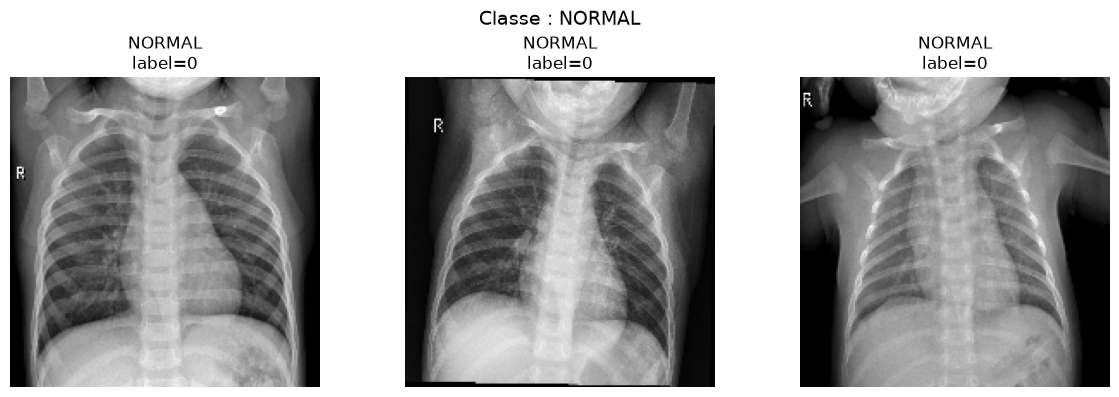

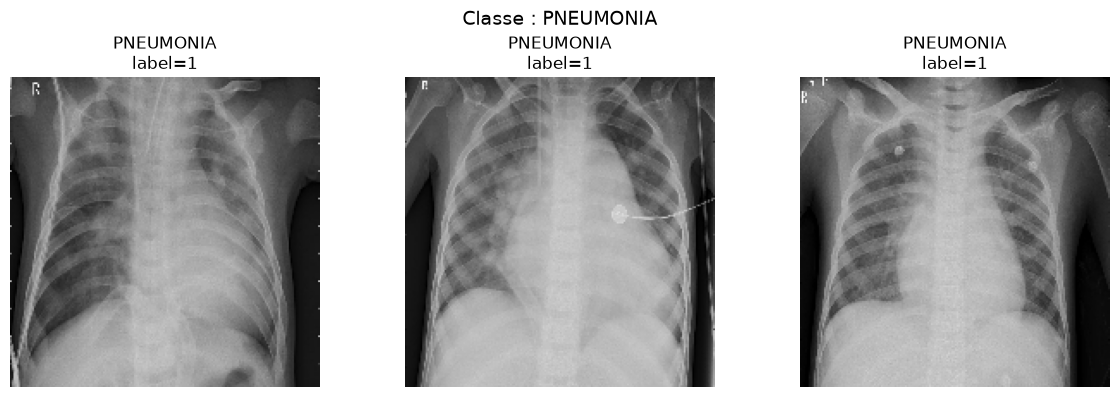

In [32]:
def afficher_echantillons(ds, class_names, n=3):
    for images, labels in ds.take(1):
        images = images.numpy().astype("uint8")
        labels = labels.numpy().flatten()
        
        for classe_idx, classe_nom in enumerate(class_names):
            idxs = np.where(labels == classe_idx)[0][:n]
            if len(idxs) == 0:
                print(f"Aucune image trouvée pour {classe_nom}")
                continue
            
            fig, axes = plt.subplots(1, len(idxs), figsize=(4 * len(idxs), 4))
            if len(idxs) == 1:
                axes = [axes]
            
            for ax, idx in zip(axes, idxs):
                ax.imshow(images[idx])
                ax.set_title(f"{classe_nom}\nlabel={labels[idx]:.0f}")
                ax.axis("off")
            
            plt.suptitle(f"Classe : {classe_nom}", fontsize=14)
            plt.tight_layout()
            plt.show()

afficher_echantillons(train_ds, train_ds.class_names, n=3)